# BTC/USDT 30-min — diagnostic tests for **momentum**

Does the data support the assumption behind `strategy_momentum_btc.ipynb` (and the momentum leg of `strategy_btc_mr_mom.ipynb`)?
Same data and the same 70 / 15 / 15 split as the strategy notebooks. The mean-reversion counterpart is `diagnostics_btc_mr.ipynb`.

| # | test | what it answers | momentum would show |
|---|---|---|---|
| 1 | data checks | is the series clean and evenly spaced? | – |
| 2 | ACF + Ljung-Box, HAC lag regressions | do 30-min returns predict the next ones? | positive autocorrelation |
| 3 | Lo–MacKinlay variance ratio (robust z\*) | does variance grow faster than a random walk? | VR(q) > 1 |
| 4 | Hurst exponent (lag-variance, R/S vs shuffled) | same question, one number | H > 0.5 |
| 5 | **MOM signal test**: past k-bar return → future return | does a big move keep going? | slope > 0 |
| 6 | **Is the edge bigger than costs?** | mean forward return when each momentum grid rule fires vs 24 bps round trip | |
| 7 | stability over time + daily-bar view | is the answer the same in every period / at daily resolution? | |

**Read-only**: the notebook only *reads* the team OneDrive file; it saves nothing (no CSV, no PNG).
Decisions should be read off the **train** column; val / test are shown only to check the answer is stable.


In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")          # kpss / statsmodels interpolation warnings
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

## 0. Settings — same as the strategy notebooks

In [2]:
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15            # chronological split, same as strategy_btc_mr_mom.ipynb
ROUND_TRIP_BPS = 2 * (10.0 + 2.0)            # 10 bps fee + 2 bps slippage per order -> 24 bps round trip

# the momentum parameter grid the strategy notebooks search
MOM_K = [1, 2, 4, 8]                         # lookback k (bars)
MOM_TH = [0.005, 0.01, 0.015, 0.02]
MOM_HOLD = [1, 4, 12]                        # holding period H (bars)
VR_Q = [2, 4, 8, 12, 24, 48, 96, 192]        # variance-ratio horizons (bars): 1h ... 4 days


## 1. Load the BTC bars (read-only)

Same search as the strategy notebooks: newest dated snapshot of
`Tsai Yi Kai - FE5209_Group_Project/data/<yymmdd>/staging/binance_spot/BTCUSDT/market_bars_30m_with_backfill.csv`.
Set `DATA_PATH` (or the `BTC_DATA_PATH` environment variable) to force a specific file. The file is opened with
`pd.read_csv` only.

In [3]:
DATA_PATH = os.environ.get("BTC_DATA_PATH")   # or paste a full path here


def shared_drive_btc_files():
    hits = []
    for base in (Path.home() / "National University of Singapore", Path.cwd(), *Path.cwd().parents):
        if base.is_dir():
            hits += base.glob("*FE5209_Group_Project/data/*/staging/binance_spot/BTCUSDT/"
                              "market_bars_30m_with_backfill.csv")
    return sorted(set(hits), key=lambda p: p.parts[-5], reverse=True)   # newest yymmdd first


path = Path(DATA_PATH) if DATA_PATH else next(iter(shared_drive_btc_files()), None)
if path is None or not path.exists():
    raise FileNotFoundError("BTC 30-min file not found - set DATA_PATH to the CSV in the team OneDrive folder")

raw = pd.read_csv(path)
raw.index = pd.DatetimeIndex(pd.to_datetime(raw["bar_open_time_utc"], utc=True)).tz_convert(None)
raw = raw.sort_index()
print("loaded:", path)
print(raw.shape, raw.index.min(), "->", raw.index.max())

loaded: C:\Users\user\National University of Singapore\Tsai Yi Kai - FE5209_Group_Project\data\260918\staging\binance_spot\BTCUSDT\market_bars_30m_with_backfill.csv
(52608, 41) 2023-09-17 00:00:00 -> 2026-09-16 23:30:00


### 1a. Data checks

In [4]:
step = raw.index.to_series().diff().dropna()
checks = pd.Series({
    "rows": len(raw),
    "duplicate timestamps": int(raw.index.duplicated().sum()),
    "gaps != 30 min": int((step != pd.Timedelta("30min")).sum()),
    "close <= 0": int((raw["close"] <= 0).sum()),
    "high < low": int((raw["high"] < raw["low"]).sum()),
    "close outside [low, high]": int(((raw["close"] > raw["high"]) | (raw["close"] < raw["low"])).sum()),
    "quality_status != pass": int((raw.get("quality_status", "pass") != "pass").sum()),
    "backfilled / synthetic bars": int((raw.get("bar_origin", "derived_complete") != "derived_complete").sum()),
})
print(checks.to_string())

raw = raw[~raw.index.duplicated(keep="last")]
close = raw["close"].astype(float)
logp = np.log(close)
ret = logp.diff().dropna()                     # 30-min log return

n = len(close)
te, ve = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
PERIODS = {"train": (close.index[0], close.index[te - 1]),
           "val": (close.index[te], close.index[ve - 1]),
           "test": (close.index[ve], close.index[-1]),
           "full": (close.index[0], close.index[-1])}
for k, (a, b) in PERIODS.items():
    print(f"{k:5s}: {a} -> {b}")


def sl(x, p):
    a, b = PERIODS[p]
    return x.loc[a:b]

rows                           52608
duplicate timestamps               0
gaps != 30 min                     0
close <= 0                         0
high < low                         0
close outside [low, high]          0
quality_status != pass             0
backfilled / synthetic bars        0
train: 2023-09-17 00:00:00 -> 2025-10-23 04:00:00
val  : 2025-10-23 04:30:00 -> 2026-04-05 13:30:00
test : 2026-04-05 14:00:00 -> 2026-09-16 23:30:00
full : 2023-09-17 00:00:00 -> 2026-09-16 23:30:00


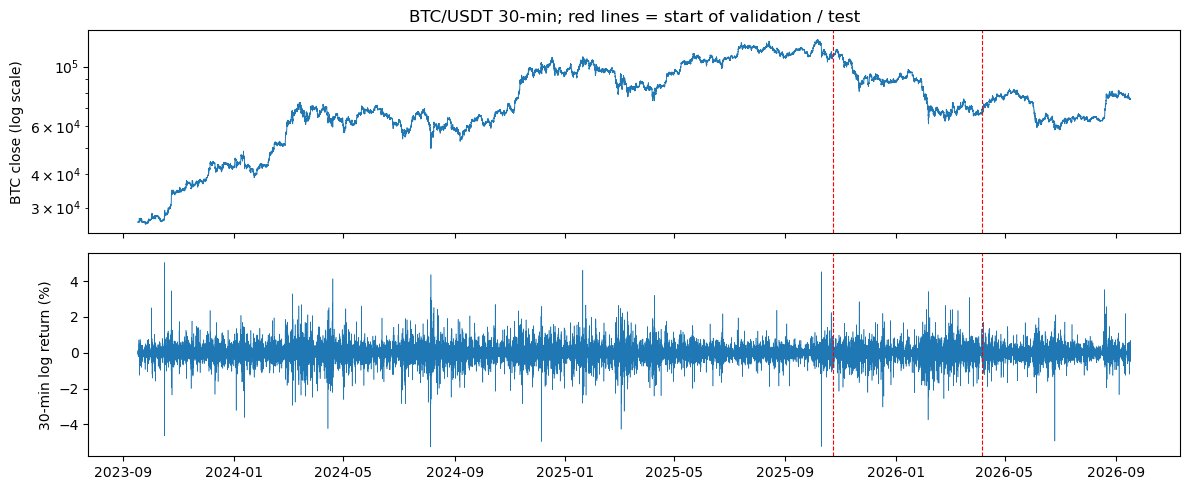

,train,val,test
count,36824.000,7891.000,7892.000
skew,-0.207,-0.251,-0.210
kurt,16.905,9.615,20.285
mean (bps),0.383,-0.614,0.165
std (bps),36.538,37.730,29.335


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(close, lw=0.7)
ax[0].set_yscale("log"); ax[0].set_ylabel("BTC close (log scale)")
ax[1].plot(ret * 100, lw=0.4)
ax[1].set_ylabel("30-min log return (%)")
for a in ax:
    for p in ("val", "test"):
        a.axvline(PERIODS[p][0], color="r", ls="--", lw=0.8)
ax[0].set_title("BTC/USDT 30-min; red lines = start of validation / test")
plt.tight_layout(); plt.show()

desc = pd.DataFrame({p: sl(ret, p).agg(["count", "mean", "std", "skew", "kurt"]) for p in ("train", "val", "test")})
desc.loc["mean (bps)"] = desc.loc["mean"] * 1e4
desc.loc["std (bps)"] = desc.loc["std"] * 1e4
desc.drop(["mean", "std"]).round(3)

**Why this matters for the tests below:** 30-min BTC returns are very fat-tailed (excess kurtosis far above 0) and
volatility clusters. Plain Ljung-Box and plain OLS t-stats assume constant variance and will **over-reject**. So every
test that matters here uses a heteroskedasticity-robust version (Lo–MacKinlay z\*, Newey-West / HAC t-stats).

## 2. Autocorrelation of 30-min returns

* Bars on the left chart: ACF of returns. Negative at small lags = short-term **reversal** (MR); positive = **continuation** (momentum).
* Right chart: ACF of |returns|, for comparison — this is volatility clustering, not a directional signal.
* Table: lag-k autocorrelation as a regression $r_t = a + \rho_k r_{t-k}$ with **HAC t-stats** (robust), plus the
  plain Ljung-Box p-value (non-robust, shown for reference).

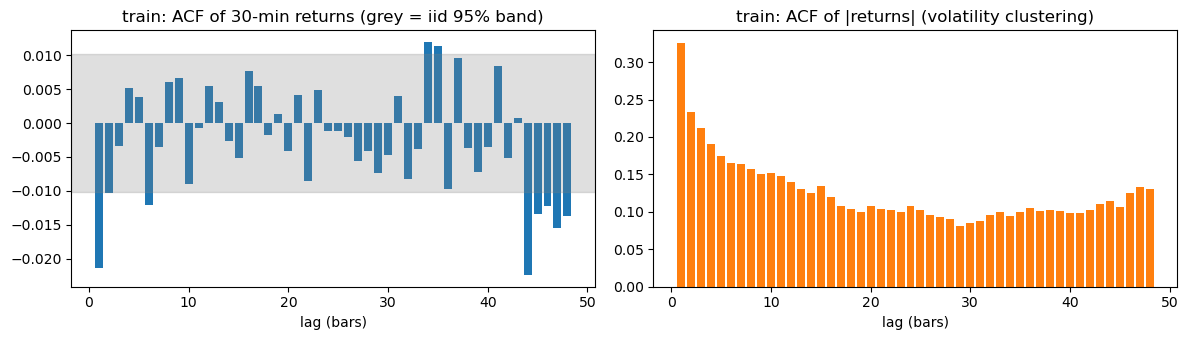

autocorr   HAC t   HAC p  Ljung-Box p (up to lag)
period lag                                                   
train  1     -0.0213 -1.8133  0.0698                   0.0000
       2     -0.0103 -1.0896  0.2759                      NaN
       4      0.0051  0.7072  0.4795                   0.0002
       12     0.0054  0.6814  0.4956                   0.0004
       48    -0.0138 -1.9517  0.0510                   0.0000
val    1     -0.0001 -0.0048  0.9962                   0.9940
       2     -0.0164 -0.9117  0.3619                      NaN
       4      0.0021  0.1302  0.8964                   0.4374
       12    -0.0164 -1.1348  0.2565                   0.0216
       48     0.0022  0.1677  0.8668                   0.0064
test   1     -0.0273 -1.3309  0.1832                   0.0153
       2     -0.0106 -0.6372  0.5240                      NaN
       4     -0.0351 -2.1338  0.0329                   0.0006
       12    -0.0099 -0.7310  0.4648                   0.0014
       48    -0.0288 -1.2550  0.2095                   0.0000
full   1     -0.0183 -1.9547  0.0506                   0.0000
       2     -0.0113 -1.4551  0.1456                      NaN
       4      0.0007  0.1054  0.9161                   0.0001
       12     0.0003  0.0447  0.9643                   0.0001
       48    -0.0125 -2.0457  0.0408                   0.0000

In [6]:
x = sl(ret, "train")
nlags = 48
band = 1.96 / np.sqrt(len(x))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(range(1, nlags + 1), acf(x, nlags=nlags)[1:], width=0.8)
ax[0].axhspan(-band, band, color="grey", alpha=0.25)
ax[0].set_title("train: ACF of 30-min returns (grey = iid 95% band)")
ax[0].set_xlabel("lag (bars)")
ax[1].bar(range(1, nlags + 1), acf(x.abs(), nlags=nlags)[1:], width=0.8, color="tab:orange")
ax[1].set_title("train: ACF of |returns| (volatility clustering)")
ax[1].set_xlabel("lag (bars)")
plt.tight_layout(); plt.show()


def hac_lag_reg(r, k):
    d = pd.concat([r, r.shift(k)], axis=1).dropna()
    d.columns = ["y", "x"]
    m = sm.OLS(d["y"], sm.add_constant(d["x"])).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    return m.params["x"], m.tvalues["x"], m.pvalues["x"]


rows = []
for p in ("train", "val", "test", "full"):
    r = sl(ret, p)
    lb = acorr_ljungbox(r, lags=[1, 4, 12, 48])
    for k in (1, 2, 4, 12, 48):
        rho, t, pv = hac_lag_reg(r, k)
        rows.append({"period": p, "lag": k, "autocorr": rho, "HAC t": t, "HAC p": pv,
                     "Ljung-Box p (up to lag)": lb["lb_pvalue"].get(k, np.nan)})
acf_tab = pd.DataFrame(rows).set_index(["period", "lag"])
acf_tab.round(4)

## 3. Variance ratio test (Lo–MacKinlay 1988, heteroskedasticity-robust z\*)

$$VR(q) = \frac{\operatorname{Var}(r_t + \dots + r_{t-q+1})}{q\,\operatorname{Var}(r_t)}$$

For a random walk VR = 1. **VR < 1 → mean reversion, VR > 1 → momentum** over a q-bar horizon.
$z^*$ is robust to changing volatility; |z\*| > 1.96 = significant at 5 %. q = 2 … 192 bars covers 1 hour to 4 days,
i.e. the momentum lookbacks/holds and the MR windows used in the strategy grids.

In [7]:
def variance_ratio(r, q):
    # Lo-MacKinlay VR(q) with overlapping q-sums and the heteroskedasticity-robust z*.
    x = np.asarray(r, dtype=float)
    T = len(x)
    mu = x.mean()
    s1 = ((x - mu) ** 2).sum() / (T - 1)
    xq = pd.Series(x).rolling(q).sum().dropna().to_numpy()
    m = q * (T - q + 1) * (1 - q / T)
    sq = ((xq - q * mu) ** 2).sum() / m
    vr = sq / s1
    d = (x - mu) ** 2
    theta = 0.0
    for j in range(1, q):
        delta_j = (d[j:] * d[:-j]).sum() / d.sum() ** 2 * T
        theta += (2 * (q - j) / q) ** 2 * delta_j
    z_star = np.sqrt(T) * (vr - 1) / np.sqrt(theta)
    z_iid = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * T))
    return vr, z_star, z_iid


rows = []
for p in ("train", "val", "test", "full"):
    for q in VR_Q:
        vr, zs, zi = variance_ratio(sl(ret, p), q)
        rows.append({"period": p, "q (bars)": q, "hours": q / 2, "VR": vr, "z* (robust)": zs,
                     "p (robust)": 2 * stats.norm.sf(abs(zs)), "z (iid, not robust)": zi})
vr_tab = pd.DataFrame(rows)
vr_tab["reading"] = np.where(vr_tab["p (robust)"] < 0.05,
                             np.where(vr_tab["VR"] < 1, "MR (sig.)", "momentum (sig.)"),
                             np.where(vr_tab["VR"] < 1, "MR-ish, n.s.", "mom-ish, n.s."))
display(vr_tab.pivot(index="q (bars)", columns="period", values="VR").round(3))
display(vr_tab.pivot(index="q (bars)", columns="period", values="z* (robust)").round(2))

period,full,test,train,val
q (bars),,,,
2,0.982,0.973,0.979,1.000
4,0.960,0.958,0.956,0.977
8,0.949,0.910,0.944,0.989
12,0.945,0.878,0.940,1.005
24,0.941,0.867,0.941,0.977
48,0.932,0.942,0.918,0.969
96,0.900,1.064,0.864,0.931
192,0.915,1.212,0.887,0.792


period,full,test,train,val
q (bars),,,,
2,-1.71,-1.19,-1.59,0.01
4,-2.20,-1.07,-1.94,-0.60
8,-2.00,-1.62,-1.77,-0.19
12,-1.81,-1.83,-1.62,0.07
24,-1.46,-1.50,-1.19,-0.24
48,-1.27,-0.48,-1.26,-0.24
96,-1.41,0.38,-1.59,-0.40
192,-0.91,0.94,-1.02,-0.90


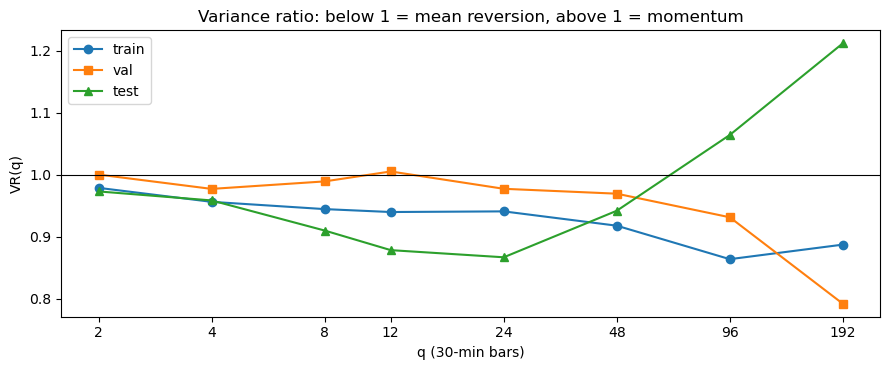

,period,q (bars),hours,VR,z* (robust),p (robust),"z (iid, not robust)",reading
0,train,2,1.0,0.9787,-1.5875,0.1124,-4.0876,"MR-ish, n.s."
1,train,4,2.0,0.9561,-1.9355,0.0529,-4.5015,"MR-ish, n.s."
2,train,8,4.0,0.9444,-1.7667,0.0773,-3.6078,"MR-ish, n.s."
3,train,12,6.0,0.9397,-1.6188,0.1055,-3.0878,"MR-ish, n.s."
4,train,24,12.0,0.9407,-1.1931,0.2328,-2.0760,"MR-ish, n.s."
5,train,48,24.0,0.9176,-1.2580,0.2084,-2.0078,"MR-ish, n.s."
6,train,96,48.0,0.8635,-1.5933,0.1111,-2.3327,"MR-ish, n.s."
7,train,192,96.0,0.8870,-1.0152,0.3100,-1.3602,"MR-ish, n.s."


In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for p, st in zip(("train", "val", "test"), ("-o", "-s", "-^")):
    s = vr_tab[vr_tab.period == p]
    ax.plot(s["q (bars)"], s["VR"], st, label=p)
ax.axhline(1, color="k", lw=0.8)
ax.set_xscale("log", base=2)
ax.set_xticks(VR_Q, [str(q) for q in VR_Q])
ax.set_xlabel("q (30-min bars)")
ax.set_ylabel("VR(q)")
ax.set_title("Variance ratio: below 1 = mean reversion, above 1 = momentum")
ax.legend(); plt.tight_layout(); plt.show()
vr_tab[vr_tab.period == "train"].round(4)

## 4. Hurst exponent

Two estimators, both on the train period:

* **Lag-variance**: $\operatorname{Var}(p_{t+\tau}-p_t) \propto \tau^{2H}$, fitted over τ = 1 … 192 bars. H < 0.5 = MR, H > 0.5 = trending.
* **Rescaled range (R/S)** on returns. R/S is biased upward in finite samples, so it is compared with the **same
  statistic on shuffled returns** (which have H = 0.5 by construction). Only the *gap* to the shuffled value means anything.

In [9]:
def hurst_lagvar(lp, lags):
    tau = np.array(lags)
    v = np.array([lp.diff(t).var() for t in tau])
    slope = np.polyfit(np.log(tau), np.log(v), 1)[0]
    return slope / 2


def hurst_rs(r, min_n=16, max_n=None):
    x = np.asarray(r, dtype=float)
    max_n = max_n or len(x) // 4
    sizes = np.unique(np.floor(np.logspace(np.log10(min_n), np.log10(max_n), 20)).astype(int))
    rs = []
    for n_ in sizes:
        chunks = x[: len(x) // n_ * n_].reshape(-1, n_)
        dev = (chunks - chunks.mean(1, keepdims=True)).cumsum(1)
        R = dev.max(1) - dev.min(1)
        S = chunks.std(1, ddof=1)
        rs.append(np.mean(R[S > 0] / S[S > 0]))
    return np.polyfit(np.log(sizes), np.log(rs), 1)[0]


rng = np.random.default_rng(0)
rows = []
for p in ("train", "val", "test", "full"):
    lp_, r_ = sl(logp, p), sl(ret, p)
    shuffled = [hurst_rs(rng.permutation(r_.to_numpy())) for _ in range(20)]
    rows.append({"period": p,
                 "H lag-variance (1-192 bars)": hurst_lagvar(lp_, range(1, 193)),
                 "H lag-variance (1-12 bars)": hurst_lagvar(lp_, range(1, 13)),
                 "H R/S": hurst_rs(r_),
                 "H R/S shuffled (mean of 20)": np.mean(shuffled),
                 "H R/S shuffled 95% range": f"{np.percentile(shuffled, 2.5):.3f}-{np.percentile(shuffled, 97.5):.3f}"})
hurst_tab = pd.DataFrame(rows).set_index("period")
hurst_tab["R/S minus shuffled"] = hurst_tab["H R/S"] - hurst_tab["H R/S shuffled (mean of 20)"]
hurst_tab.round(3)

,H lag-variance (1-192 bars),H lag-variance (1-12 bars),H R/S,H R/S shuffled (mean of 20),H R/S shuffled 95% range,R/S minus shuffled
period,,,,,,
train,0.486,0.488,0.532,0.541,0.513-0.564,-0.009
val,0.469,0.501,0.556,0.539,0.502-0.580,0.017
test,0.542,0.473,0.551,0.547,0.514-0.581,0.004
full,0.492,0.489,0.536,0.535,0.514-0.556,0.001


## 5. Momentum signal test — does the past k-bar return predict the next H bars?

$$\log P_{t+H} - \log P_t = a + \beta\, R^{(k)}_t + \varepsilon, \qquad R^{(k)}_t = \log P_t - \log P_{t-k}$$

**Momentum needs β > 0**; β < 0 means the move tends to reverse (that would support MR instead).

In [10]:
def fwd(h):
    return logp.shift(-h) - logp


def hac_slope(y, x, lags):
    d = pd.concat([y, x], axis=1).dropna()
    d.columns = ["y", "x"]
    m = sm.OLS(d["y"], sm.add_constant(d["x"])).fit(cov_type="HAC", cov_kwds={"maxlags": max(lags, 1)})
    return m.params["x"], m.tvalues["x"]


RK = {k: logp.diff(k) for k in MOM_K}
rows = []
for p in ("train", "val", "test"):
    for k in MOM_K:
        for h in MOM_HOLD:
            b, t = hac_slope(sl(fwd(h), p), sl(RK[k], p), max(k, h))
            rows.append({"period": p, "k": k, "H": h, "beta": b, "HAC t": t})
mom_reg = pd.DataFrame(rows)
mom_reg["reading"] = np.where(mom_reg["HAC t"] > 1.96, "momentum (sig.)",
                              np.where(mom_reg["HAC t"] < -1.96, "reversal (sig.)", "n.s."))
mom_reg.pivot_table(index=["k", "H"], columns="period", values=["beta", "HAC t"]).round(3)

HAC t                 beta              
period   test  train    val   test  train    val
k H                                             
1 1    -1.292 -1.698 -0.004 -0.027 -0.021 -0.000
  4    -1.597 -1.588 -0.794 -0.053 -0.030 -0.029
  12   -1.917 -1.194 -0.523 -0.090 -0.033 -0.027
2 1    -1.283 -1.902 -0.598 -0.019 -0.016 -0.008
  4    -1.516 -1.120 -0.416 -0.044 -0.018 -0.013
  12   -1.902 -0.848 -0.445 -0.085 -0.021 -0.022
4 1    -1.471 -1.537 -0.779 -0.014 -0.008 -0.007
  4    -2.105 -1.016  0.484 -0.051 -0.012  0.012
  12   -1.873 -0.533 -0.280 -0.079 -0.012 -0.013
8 1    -2.133 -1.459  0.793 -0.013 -0.005  0.004
  4    -2.251 -0.703  0.795 -0.040 -0.007  0.014
  12   -1.046 -0.117 -0.455 -0.040 -0.002 -0.018

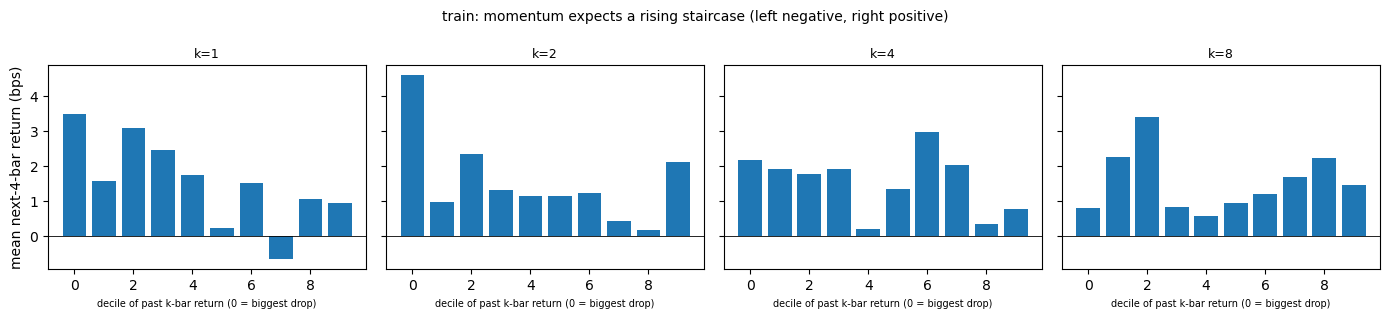

In [11]:
fig, axes = plt.subplots(1, len(MOM_K), figsize=(14, 3.2), sharey=True)
for ax, k in zip(axes, MOM_K):
    d = pd.concat([sl(RK[k], "train"), sl(fwd(4), "train") * 1e4], axis=1).dropna()
    d.columns = ["R", "f"]
    g = d.groupby(pd.qcut(d["R"], 10, labels=False))["f"].mean()
    ax.bar(g.index, g.values)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"k={k}", fontsize=9)
    ax.set_xlabel("decile of past k-bar return (0 = biggest drop)", fontsize=7)
axes[0].set_ylabel("mean next-4-bar return (bps)")
fig.suptitle("train: momentum expects a rising staircase (left negative, right positive)", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Is the edge bigger than the trading cost?

Statistical significance is not enough: a round trip costs **24 bps**. Here every rule in the momentum grid is
reduced to its **entry events** (first bar of each signal episode, so events do not overlap much) and we measure the
average **signed** forward return in the trade direction, before costs.

* MOM: direction $=\text{sign}(R)$ when $|R| >$ threshold; forward horizon = the hold H.

A rule can only make money after costs if **mean signed return > 24 bps** (and t-stat clearly > 0).
`excess vs drift` removes what a random entry in the same direction would have earned (BTC drifted up in train, so
long-only rules look better than the signal really is).


In [12]:
def entry_events(active):
    # first bar of each run where the condition is on
    return active & ~active.shift(1, fill_value=False)


def event_stats(direction, fwd_ret, period):
    d = pd.concat([direction, fwd_ret], axis=1).dropna()
    d.columns = ["dir", "f"]
    d = sl(d[d["dir"] != 0], period)
    s = d["dir"] * d["f"] * 1e4
    n_ = len(s)
    # drift-adjusted: subtract what a random entry in the same direction would have earned in this period
    drift = sl(fwd_ret, period).mean() * 1e4
    excess = s - d["dir"] * drift
    return n_, s.mean() if n_ else np.nan, (s.mean() / s.std(ddof=1) * np.sqrt(n_)) if n_ > 2 else np.nan, \
        (s > 0).mean() if n_ else np.nan, excess.mean() if n_ else np.nan


rows = []
for k in MOM_K:
    for th in MOM_TH:
        up, dn = entry_events(RK[k] > np.log1p(th)), entry_events(RK[k] < np.log1p(-th))
        for side_name, allow_short in (("long/short", True), ("long-only", False)):
            direction = pd.Series(0, index=RK[k].index) + up.astype(int) - (dn.astype(int) if allow_short else 0)
            for h in MOM_HOLD:
                for p in ("train", "val", "test"):
                    n_, m_, t_, hit, ex_ = event_stats(direction, fwd(h), p)
                    rows.append({"rule": "MOM", "side": side_name, "params": f"k={k}, th={th:.1%}", "h": h,
                                 "period": p, "events": n_, "mean signed bps": m_, "t": t_, "hit rate": hit, "excess vs drift bps": ex_})
ev = pd.DataFrame(rows)
ev["beats 24 bps"] = ev["mean signed bps"] > ROUND_TRIP_BPS

summary = (ev[ev.period == "train"].groupby(["rule", "side"])
           .agg(rules_tested=("params", "size"),
                share_mean_gt_0=("mean signed bps", lambda s: (s > 0).mean()),
                share_beats_cost=("beats 24 bps", "mean"),
                share_t_gt_2=("t", lambda s: (s > 2).mean()),
                median_mean_bps=("mean signed bps", "median"),
                median_excess_vs_drift_bps=("excess vs drift bps", "median")))
summary.round(3)


rules_tested  share_mean_gt_0  share_beats_cost  share_t_gt_2  median_mean_bps  median_excess_vs_drift_bps
rule side                                                                                                                  
MOM  long-only             48            0.833             0.021         0.021            2.514                       0.601
     long/short            48            0.333             0.000         0.000           -0.863                      -0.959

In [13]:
# the 10 best-looking MOM rules on TRAIN, and what happened to them on val / test
wide = ev.pivot_table(index=["rule", "side", "params", "h"], columns="period",
                      values=["events", "mean signed bps", "t", "excess vs drift bps"])
wide.columns = [f"{p}_{m}" for m, p in wide.columns]
cols = ["train_events", "train_mean signed bps", "train_excess vs drift bps", "train_t", "val_mean signed bps", "val_t", "test_mean signed bps", "test_t"]
print("MOM: top 10 by train mean signed return (bps, before 24 bps costs)")
display(wide.loc["MOM"].sort_values("train_mean signed bps", ascending=False)[cols].head(10).round(2))


MOM: top 10 by train mean signed return (bps, before 24 bps costs)


train_events  train_mean signed bps  train_excess vs drift bps  train_t  val_mean signed bps  val_t  test_mean signed bps  test_t
side      params       h                                                                                                                                    
long-only k=2, th=2.0% 12         116.0                  24.04                      19.42     1.24               -13.48  -0.49                 20.41    0.55
          k=1, th=1.5% 12         127.0                  21.11                      16.49     0.97                21.45   0.68                -20.19   -0.56
                       4          127.0                  17.51                      15.97     1.11                16.63   0.59                -16.68   -0.64
          k=2, th=1.5% 12         262.0                  17.08                      12.46     1.47                -2.92  -0.11                -12.85   -0.59
          k=4, th=1.5% 12         417.0                  15.59                      10.97     1.64               -15.33  -0.95                 -5.92   -0.34
          k=4, th=2.0% 12         216.0                  15.53                      10.91     1.13               -21.46  -0.99                -11.95   -0.64
          k=1, th=1.0% 12         383.0                  13.17                       8.55     1.29                 8.69   0.40                 -4.43   -0.25
          k=2, th=1.0% 12         642.0                  10.87                       6.25     1.50                -5.84  -0.39                 -0.33   -0.02
          k=1, th=0.5% 12        1709.0                  10.75                       6.13     2.65                -2.22  -0.27                 -2.94   -0.35
          k=2, th=2.0% 4          116.0                  10.63                       9.09     0.72               -12.74  -0.52                  0.19    0.01

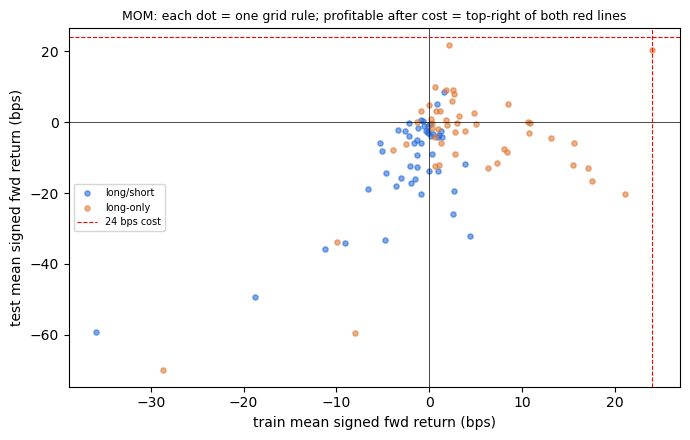

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
w_ = wide.loc["MOM"]
for side, col in (("long/short", "#2a6fdb"), ("long-only", "#e07b39")):
    s = w_.xs(side, level="side")
    ax.scatter(s["train_mean signed bps"], s["test_mean signed bps"], s=14, alpha=0.6, color=col, label=side)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.axhline(ROUND_TRIP_BPS, color="r", ls="--", lw=0.8, label="24 bps cost")
ax.axvline(ROUND_TRIP_BPS, color="r", ls="--", lw=0.8)
ax.set_xlabel("train mean signed fwd return (bps)")
ax.set_ylabel("test mean signed fwd return (bps)")
ax.set_title("MOM: each dot = one grid rule; profitable after cost = top-right of both red lines", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 7. Stability: rolling 90-day statistics, and the daily-bar view

The answer can flip by regime. Left: rolling lag-1 autocorrelation and VR(48) over 90-day windows. Right: the same
variance-ratio test on **daily** closes (00:00 UTC), which is the resolution earlier project diagnostics used.

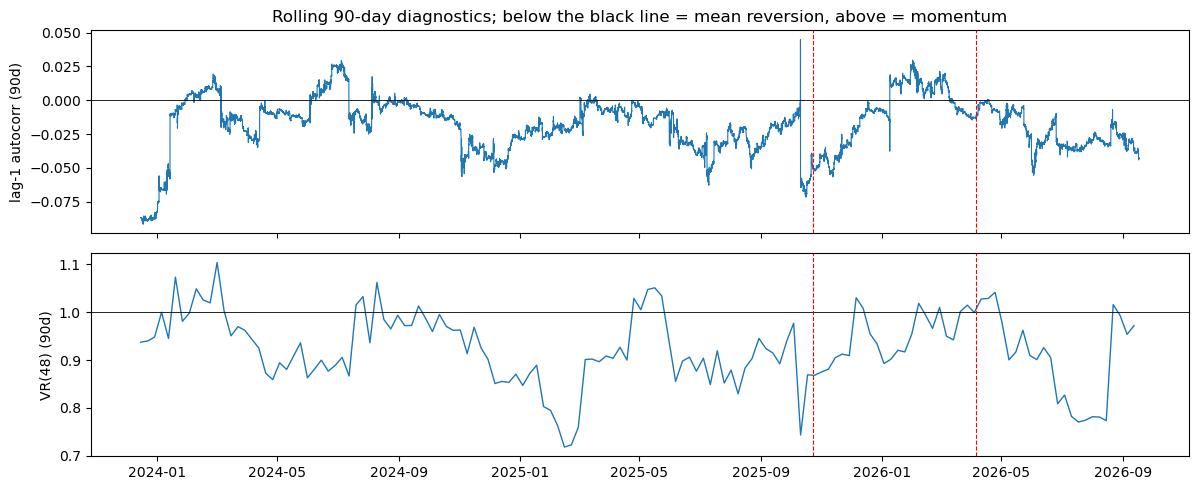

share of 90-day windows with VR(48) < 1: 0.826


In [15]:
win = 48 * 90
roll_ac1 = ret.rolling(win).apply(lambda a: pd.Series(a).autocorr(1), raw=True)
step_ = 48 * 7                                    # weekly evaluation points for VR(48), faster than every bar
vr_pts = {ret.index[i]: variance_ratio(ret.iloc[i - win:i], 48)[0] for i in range(win, len(ret), step_)}
roll_vr = pd.Series(vr_pts)

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(roll_ac1, lw=0.8); ax[0].axhline(0, color="k", lw=0.6); ax[0].set_ylabel("lag-1 autocorr (90d)")
ax[1].plot(roll_vr, lw=1); ax[1].axhline(1, color="k", lw=0.6); ax[1].set_ylabel("VR(48) (90d)")
for a in ax:
    for p in ("val", "test"):
        a.axvline(PERIODS[p][0], color="r", ls="--", lw=0.8)
ax[0].set_title("Rolling 90-day diagnostics; below the black line = mean reversion, above = momentum")
plt.tight_layout(); plt.show()
print("share of 90-day windows with VR(48) < 1:", round((roll_vr < 1).mean(), 3))

In [16]:
daily = close.resample("1D").last().dropna()
dret = np.log(daily).diff().dropna()
rows = []
for p in ("train", "val", "test", "full"):
    r = sl(dret, p)
    row = {"period": p, "days": len(r), "lag-1 autocorr": r.autocorr(1)}
    for q in (2, 5, 10, 20):
        vr, zs, _ = variance_ratio(r, q)
        row[f"VR({q}d)"] = vr
        row[f"z*({q}d)"] = zs
    rows.append(row)
pd.DataFrame(rows).set_index("period").round(3)

,days,lag-1 autocorr,VR(2d),z*(2d),VR(5d),z*(5d),VR(10d),z*(10d),VR(20d),z*(20d)
period,,,,,,,,,,
train,767,-0.067,0.935,-1.438,0.930,-0.747,0.899,-0.712,0.927,-0.362
val,164,-0.095,0.913,-0.534,0.741,-0.894,0.800,-0.524,1.004,0.009
test,164,0.100,1.113,0.998,1.401,1.742,1.662,2.095,1.847,2.035
full,1095,-0.051,0.951,-1.081,0.955,-0.511,0.978,-0.174,1.066,0.377


## 8. Verdict table (auto-built from the numbers above, train period)


In [17]:
tr_vr = vr_tab[vr_tab.period == "train"].set_index("q (bars)")
tr_acf = acf_tab.loc["train"]
tr_h = hurst_tab.loc["train"]
mom_tr = mom_reg[mom_reg.period == "train"]


def sig_count(s, cond):
    return f"{int(cond(s).sum())} / {len(s)}"


verdict = pd.DataFrame([
    ["ACF lag-1 (HAC)", f"rho = {tr_acf.loc[1, 'autocorr']:.4f}, t = {tr_acf.loc[1, 'HAC t']:.2f}",
     "MR" if tr_acf.loc[1, "autocorr"] < 0 else "momentum",
     "significant" if abs(tr_acf.loc[1, "HAC t"]) > 1.96 else "not significant"],
    ["Variance ratio, q=2..192", "VR range " + f"{tr_vr['VR'].min():.3f}-{tr_vr['VR'].max():.3f}",
     "MR" if (tr_vr["VR"] < 1).mean() > 0.5 else "momentum",
     f"{int((tr_vr['p (robust)'] < 0.05).sum())} of {len(tr_vr)} horizons significant (robust z*)"],
    ["Hurst lag-variance", f"H = {tr_h['H lag-variance (1-192 bars)']:.3f}",
     "MR" if tr_h["H lag-variance (1-192 bars)"] < 0.5 else "momentum", "no formal test; compare with 0.5"],
    ["Hurst R/S vs shuffled", f"gap = {tr_h['R/S minus shuffled']:+.3f}",
     "MR" if tr_h["R/S minus shuffled"] < 0 else "momentum",
     f"shuffled 95% range {tr_h['H R/S shuffled 95% range']}"],
    ["MOM signal: fwd return on past return", f"positive & sig.: {sig_count(mom_tr, lambda s: s['HAC t'] > 1.96)}",
     "supports momentum" if (mom_tr["HAC t"] > 1.96).any() else "does not support momentum",
     f"negative & sig. (reversal): {sig_count(mom_tr, lambda s: s['HAC t'] < -1.96)}"],
    ["Edge vs 24 bps cost (MOM)", f"{summary.loc[('MOM', 'long/short'), 'share_beats_cost']:.0%} (L/S), "
                                  f"{summary.loc[('MOM', 'long-only'), 'share_beats_cost']:.0%} (LO) of rules beat cost on train", "", ""],
], columns=["test", "result", "points to", "note"])
verdict


,test,result,points to,note
0,ACF lag-1 (HAC),"rho = -0.0213, t = -1.81",MR,not significant
1,"Variance ratio, q=2..192",VR range 0.864-0.979,MR,0 of 8 horizons significant (robust z*)
2,Hurst lag-variance,H = 0.486,MR,no formal test; compare with 0.5
3,Hurst R/S vs shuffled,gap = -0.009,MR,shuffled 95% range 0.513-0.564
4,MOM signal: fwd return on past return,positive & sig.: 0 / 12,does not support momentum,negative & sig. (reversal): 0 / 12
5,Edge vs 24 bps cost (MOM),"0% (L/S), 2% (LO) of rules beat cost on train",,


## 9. What this means for the momentum strategy

*(written after running on the 2026-09-18 snapshot; re-read the tables above if the data changes)*

**Data.** 52,608 clean 30-min bars (2023-09-17 → 2026-09-16), no gaps, duplicates or synthetic bars — the
results below are not a data artefact.

**Return-level tests** (shared with the MR notebook): lag-1 autocorrelation ≈ −0.02 and VR(q) < 1 at every horizon
from 1 h to 4 days on train, none significant with robust z\*; Hurst ≈ 0.49. If anything this leans slightly
*against* momentum, but it is indistinguishable from a random walk.

**Momentum**
* At 30-min resolution the evidence points the **wrong way** for momentum: all 12 (k, H) slopes on train are negative
  (weak reversal), none significant. Decile charts show no rising staircase.
* At **daily** resolution BTC is mixed: train VR < 1 (n.s.), but the **test** window shows VR > 1 and significant at 10–20 days.
  That is where a "BTC leans momentum" reading can come from — it is a daily, recent-period effect, not a 30-min one.

**Costs.** No long/short momentum rule clears the 24 bps round trip on train. Most long-only rules that look
good are BTC's upward drift (median `excess vs drift` ≈ 0).

**Bottom line for the report.** At 30-min resolution momentum is **not supported**: the signal slopes point the
wrong way and no rule beats costs, which agrees with the backtest (negative test Sharpe). The only place with some
momentum evidence is **longer-horizon (multi-day)**, and that comes from the test period only, so it should be framed
as a hypothesis rather than a validated edge.
